# Paired NPY Denoising: Training and Comparative Experiments

**Inputs:** `CleanImages.npy` and `NoisyImages.npy`, expected shape `(N, H, W, 1)`.
**Outputs:** model checkpoints, training histories, PSNR/SSIM/gradient-error tables, paired differences, runtime measurements, and fixed-region comparisons.

Compare **Noisy input**, **DnCNN**, **U-Net MSE**, and **U-Net MSE + gradient**.

The supplied data show stripe-like interference and values outside `[0,1]`. We preserve values, apply one training-derived affine scale to both arrays, and do not assume that the data are FMD or Poisson–Gaussian.

Start in **smoke mode**. It checks the pipeline with a small training budget, limited validation samples, and training images for the final-stage debug evaluation. It does not evaluate restored test images. These outputs are debugging results, not final research results. Then switch to **full mode** and restart the kernel.

Array order must encode the correct pairing. Confirm this with the TA. Sample-index splitting is provisional until independence is confirmed or group IDs are supplied.

Sources: [DnCNN](https://github.com/cszn/DnCNN), [FMD baseline](https://github.com/yinhaoz/denoising-fluorescence).


In [1]:
# Uncomment and run once, then restart the kernel.
# For GPU training, install the PyTorch build appropriate for your hardware.
# %pip install torch numpy pandas matplotlib scikit-image tqdm nbformat


In [2]:
from pathlib import Path
import copy
import json
import random
import time
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from tqdm.auto import tqdm

CFG = {
    # Change this directory if you move the supplied files.
    'data_dir': 'C:/Users/15174/PyCharmMiscProject',
    'clean_file': 'CleanImages.npy',
    'noisy_file': 'NoisyImages.npy',
    'metadata_csv': None,  # Optional: one row per index, with group_id.
    'independent_images_confirmed': False,  # Set True only after confirmation.
    'mode': 'full',       # 'smoke' first, then 'full'
    'output_root': './results_npy',
    'seed': 42,
    'patch_size': 128,
    'batch_size': 8,
    'learning_rate': 1e-3,
    'unet_width': 32,
    'dncnn_depth': 17,
    'clip_predictions': False,
}
assert CFG['mode'] in {'smoke', 'full'}
SMOKE = CFG['mode'] == 'smoke'
CFG.update({
    'epochs': 2 if SMOKE else 30,
    'steps_per_epoch': 5 if SMOKE else 100,
    'lambda_candidates': [0.0, 0.01] if SMOKE else [0.0, 0.01, 0.05, 0.1],
    'validation_limit': 8 if SMOKE else None,
    'test_limit': 8 if SMOKE else None,
})
assert CFG['patch_size'] >= 16 and CFG['patch_size'] % 4 == 0
DATA_DIR = Path(CFG['data_dir']).resolve()
OUT = Path(CFG['output_root']).resolve() / f"{CFG['mode']}_seed_{CFG['seed']}"
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print('Device:', DEVICE, '| Mode:', CFG['mode'], '| Output:', OUT)


Device: cpu | Mode: full | Output: C:\Users\15174\PyCharmMiscProject\results_npy\full_seed_42


## 1. Load and audit the paired arrays

Memory mapping avoids loading both float64 arrays completely into RAM. Individual patches/images are converted to float32 when used. No source files are modified. Matching shapes do not prove correct alignment or pairing.


Clean (1000, 256, 256, 1) float64 range: 0.012926957488356433 1.257205144425902
Noisy (1000, 256, 256, 1) float64 range: -0.0963303406824996 1.441292538322902


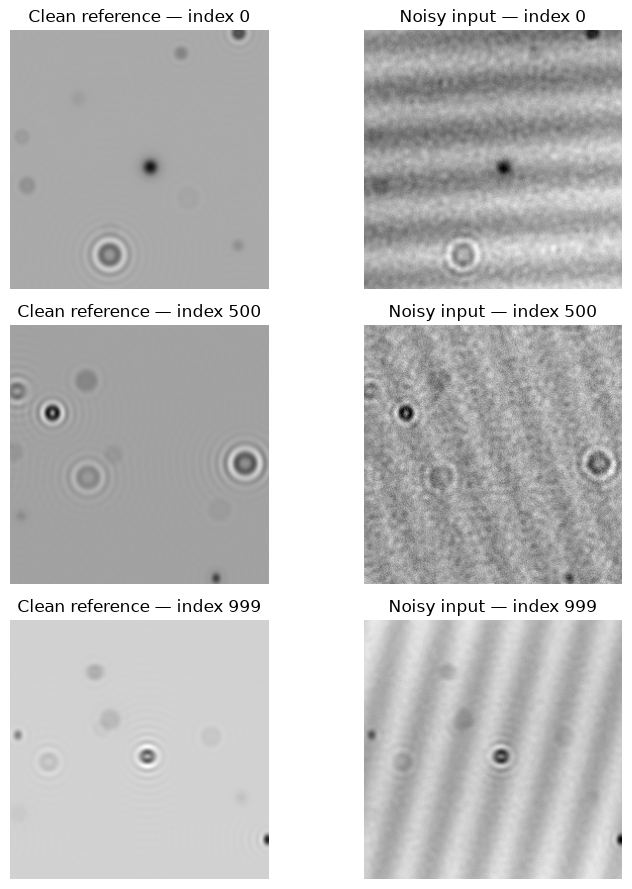

In [3]:
clean = np.load(DATA_DIR / CFG['clean_file'], mmap_mode='r', allow_pickle=False)
noisy = np.load(DATA_DIR / CFG['noisy_file'], mmap_mode='r', allow_pickle=False)
assert clean.shape == noisy.shape, 'Pair shapes differ.'
assert clean.ndim == 4 and clean.shape[-1] == 1, 'Expected NHWC grayscale arrays.'
N, H, W, C = clean.shape
assert min(H, W) >= CFG['patch_size']
assert np.issubdtype(clean.dtype, np.number) and np.issubdtype(noisy.dtype, np.number)
for name, array in [('Clean', clean), ('Noisy', noisy)]:
    for start in range(0, N, 16):
        assert np.isfinite(array[start:start+16]).all(), f'{name} has NaN/Inf.'
    print(name, array.shape, array.dtype, 'range:', float(array.min()), float(array.max()))

preview_indices = sorted(set([0, N//2, N-1]))
fig, axes = plt.subplots(len(preview_indices), 2, figsize=(8, 3*len(preview_indices)), squeeze=False)
for r, index in enumerate(preview_indices):
    x, y = noisy[index, :, :, 0], clean[index, :, :, 0]
    low, high = min(x.min(), y.min()), max(x.max(), y.max())
    for ax, image, title in zip(axes[r], [y, x], ['Clean reference', 'Noisy input']):
        ax.imshow(image, cmap='gray', vmin=low, vmax=high)
        ax.set_title(f'{title} — index {index}')
        ax.axis('off')
plt.tight_layout()
plt.show()


## 2. Fixed split: keep paired indices and related fields together

Without metadata, the 1,000 images are provisionally treated as 1,000 independent samples (700/150/150). This may overestimate generalization if images are related. Do not present it as a verified field-level split.

If the TA supplies metadata, create a CSV with `index,group_id`, one row per image. Repeated acquisitions, channels, patches, or augmentations of the same original field must share `group_id`. Optional `noise_level` must describe an independently known acquisition/generation condition. Do not create noise levels from test Clean images.

The split is determined by the seed and groups and saved for reproducibility. Smoke/full modes use the same underlying split.


In [4]:
if CFG['metadata_csv'] is not None:
    frame = pd.read_csv(CFG['metadata_csv'], dtype={'group_id': str}).sort_values('index').reset_index(drop=True)
    assert {'index', 'group_id'} <= set(frame.columns)
    assert frame['index'].tolist() == list(range(N)), 'Metadata must contain every index exactly once.'
    assert frame['group_id'].notna().all() and frame['group_id'].ne('').all()
    split_status = 'Grouped split; verify group IDs with the TA'
else:
    frame = pd.DataFrame({'index': np.arange(N), 'group_id': [f'sample_{i:05d}' for i in range(N)]})
    split_status = ('Independent sample split, confirmed by user' if CFG['independent_images_confirmed']
                    else 'PROVISIONAL sample split; sample independence unconfirmed')
    if not CFG['independent_images_confirmed']:
        warnings.warn(split_status)
if 'noise_level' not in frame:
    frame['noise_level'] = 'provided_condition'
assert frame['noise_level'].notna().all()
frame['noise_level'] = frame['noise_level'].astype(str)

groups = sorted(frame['group_id'].unique())
assert len(groups) >= 7, 'Too few independent groups for this split.'
random.Random(CFG['seed']).shuffle(groups)
n_val, n_test = max(1, round(0.15*len(groups))), max(1, round(0.15*len(groups)))
labels = {g: 'train' for g in groups}
labels.update({g: 'val' for g in groups[:n_val]})
labels.update({g: 'test' for g in groups[n_val:n_val+n_test]})
frame['split'] = frame['group_id'].map(labels)
assert frame.groupby('group_id')['split'].nunique().max() == 1
train_frame = frame[frame['split'] == 'train'].reset_index(drop=True)
val_frame = frame[frame['split'] == 'val'].reset_index(drop=True)
test_frame = frame[frame['split'] == 'test'].reset_index(drop=True)
frame.to_csv(OUT / 'split_manifest.csv', index=False)
display(frame.groupby('split').agg(images=('index', 'size'), groups=('group_id', 'nunique')))
display(pd.crosstab(frame['split'], frame['noise_level']))
print(split_status)

def evaluation_subset(part, limit):
    return part if limit is None else part.iloc[:limit].copy()

VAL_EVAL = evaluation_subset(val_frame, CFG['validation_limit'])
TEST_EVAL = (evaluation_subset(train_frame, CFG['test_limit']) if SMOKE else test_frame)
EVALUATION_SPLIT = 'training subset for debugging' if SMOKE else 'held-out test set'
print('Final-stage evaluation uses:', EVALUATION_SPLIT)


C:\Users\15174\AppData\Local\Temp\ipykernel_11008\803843740.py:12: UserWarning: PROVISIONAL sample split; sample independence unconfirmed
  warnings.warn(split_status)


,images,groups
split,,
test,150,150
train,700,700
val,150,150


noise_level,provided_condition
split,
test,150
train,700
val,150


PROVISIONAL sample split; sample independence unconfirmed
Final-stage evaluation uses: held-out test set


## 3. Common scale derived from training references only

Use `(image - offset) / scale` for BOTH arrays. This is a declared fallback when no calibrated scale is available. Training Clean extrema define the reference range; Noisy and held-out images may remain outside `[0,1]`. They are not clipped.

All metrics use `data_range=1.0` in this common normalized coordinate system. This corresponds to `data_range=scale` in original units. Never recompute the range per image or per method. Report this convention; replace it with the TA's physical scale if available.


In [5]:
train_indices = train_frame['index'].to_numpy()
offset, maximum = float('inf'), -float('inf')
for start in range(0, len(train_indices), 16):
    block = clean[train_indices[start:start+16]]
    offset = min(offset, float(block.min()))
    maximum = max(maximum, float(block.max()))
scale = maximum - offset
assert scale > 0

def normalize(image):
    return (np.asarray(image, dtype=np.float32) - offset) / scale

def read_pair(index):
    return normalize(noisy[index, :, :, 0]), normalize(clean[index, :, :, 0])

print('Training-derived offset:', offset, 'scale:', scale)


Training-derived offset: 0.028189116106189457 scale: 1.2216391114519227


In [6]:
class PairedPatches(Dataset):
    def __init__(self, part):
        self.group_indices = [g['index'].to_numpy() for _, g in part.groupby('group_id')]
    def __len__(self):
        return CFG['steps_per_epoch'] * CFG['batch_size']
    def __getitem__(self, unused_index):
        # Sample groups uniformly, then select an acquisition within a group.
        candidates = self.group_indices[random.randrange(len(self.group_indices))]
        index = int(candidates[random.randrange(len(candidates))])
        p = CFG['patch_size']
        top, left = random.randint(0, H-p), random.randint(0, W-p)
        x = normalize(noisy[index, top:top+p, left:left+p, 0])
        y = normalize(clean[index, top:top+p, left:left+p, 0])
        k = random.randrange(4)
        x, y = np.rot90(x, k), np.rot90(y, k)
        if random.random() < 0.5:
            x, y = np.fliplr(x), np.fliplr(y)
        return torch.from_numpy(x.copy())[None], torch.from_numpy(y.copy())[None]

def make_loader():
    # workers=0 keeps this framework's random augmentation order reproducible.
    return DataLoader(PairedPatches(train_frame), batch_size=CFG['batch_size'], num_workers=0)


## 4. DnCNN, U-Net, and the edge-preserving loss

DnCNN predicts `Noisy - Clean`; returning `input - predicted_residual` makes output-space MSE equivalent to residual MSE. U-Net directly predicts the restored image.

`loss = MSE + lambda * gradient_MAE`, where gradient MAE averages the horizontal and vertical finite-difference errors. The two U-Net conditions share architecture, initial parameters, batches, learning rate, and training steps. Only lambda changes.


In [7]:
class DnCNN(nn.Module):
    def __init__(self, depth=17, width=64):
        super().__init__()
        layers = [nn.Conv2d(1, width, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(width, width, 3, padding=1, bias=False),
                       nn.BatchNorm2d(width), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(width, 1, 3, padding=1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return x - self.net(x)

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU(inplace=True))

class SmallUNet(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.enc1, self.enc2 = conv_block(1, width), conv_block(width, width*2)
        self.bottom = conv_block(width*2, width*4)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(width*4, width*2, 2, stride=2)
        self.dec2 = conv_block(width*4, width*2)
        self.up1 = nn.ConvTranspose2d(width*2, width, 2, stride=2)
        self.dec1 = conv_block(width*2, width)
        self.out = nn.Conv2d(width, 1, 1)
        # Start with zero correction: initial prediction equals the input
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        b = self.bottom(self.pool(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return  x + self.out(d1)

def gradient_loss(pred, target):
    dx = torch.mean(torch.abs((pred[..., :, 1:] - pred[..., :, :-1]) -
                             (target[..., :, 1:] - target[..., :, :-1])))
    dy = torch.mean(torch.abs((pred[..., 1:, :] - pred[..., :-1, :]) -
                             (target[..., 1:, :] - target[..., :-1, :])))
    return (dx + dy) / 2

def restoration_loss(pred, target, edge_weight=0.0):
    return nn.functional.mse_loss(pred, target) + edge_weight * gradient_loss(pred, target)


In [8]:
def for_metrics(pred):
    return np.clip(pred, 0, 1) if CFG['clip_predictions'] else pred

def metrics(pred, reference):
    pred = for_metrics(pred)
    assert pred.shape == reference.shape and np.isfinite(pred).all()
    mse = float(np.mean((pred.astype(np.float64)-reference)**2))
    grad = (np.abs(np.diff(pred, axis=0)-np.diff(reference, axis=0)).mean() +
            np.abs(np.diff(pred, axis=1)-np.diff(reference, axis=1)).mean()) / 2
    return {'mse': mse,
            'psnr': float(peak_signal_noise_ratio(reference, pred, data_range=1.0)),
            'ssim': float(structural_similarity(reference, pred, data_range=1.0)),
            'gradient_mae': float(grad)}

@torch.no_grad()
def predict_image(model, image):
    model.eval()
    h, w = image.shape
    padded = np.pad(image, ((0, (-h)%4), (0, (-w)%4)), mode='reflect')
    tensor = torch.from_numpy(padded.copy())[None, None].to(DEVICE)
    return model(tensor)[0, 0, :h, :w].cpu().numpy()

def synchronize_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def validate(model):
    rows = []
    for row in VAL_EVAL.itertuples(index=False):
        x, y = read_pair(row.index)
        rows.append({'group_id': row.group_id, **metrics(predict_image(model, x), y)})
    return pd.DataFrame(rows).groupby('group_id')[['mse','psnr','ssim','gradient_mae']].mean().mean().to_dict()


## 5. Small shape/gradient check

This check does not use test data and does not produce scientific results. A finite loss/gradient does not prove that training converges; inspect the training and validation curves too.


In [9]:
seed_everything(CFG['seed'])
xb, yb = next(iter(make_loader()))
xb, yb = xb[:2].to(DEVICE), yb[:2].to(DEVICE)
for model in [SmallUNet(CFG['unet_width']), DnCNN(CFG['dncnn_depth'])]:
    model = model.to(DEVICE)
    pred = model(xb)
    assert pred.shape == yb.shape
    loss = restoration_loss(pred, yb, 0.01)
    assert torch.isfinite(loss)
    loss.backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    print(type(model).__name__, 'loss:', loss.item(), 'shape:', tuple(pred.shape))
del model, xb, yb, pred, loss


SmallUNet loss: 0.004033689387142658 shape: (2, 1, 128, 128)
DnCNN loss: 0.1995776891708374 shape: (2, 1, 128, 128)


In [10]:
def train_model(model, name, edge_weight=0.0):
    seed_everything(CFG['seed'])
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG['learning_rate'])
    loader = make_loader()
    best_psnr, history = -float('inf'), []
    path = OUT / f'{name}.pt'
    synchronize_device()
    started = time.perf_counter()
    for epoch in range(1, CFG['epochs']+1):
        model.train()
        total_loss = 0.0
        for xb, yb in tqdm(loader, desc=f'{name}: epoch {epoch}', leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = restoration_loss(model(xb), yb, edge_weight)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite loss; check data and learning rate.')
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        scores = validate(model)
        history.append({'epoch': epoch, 'train_loss': total_loss/len(loader), **scores})
        if scores['psnr'] > best_psnr:
            best_psnr = scores['psnr']
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'validation': scores, 'lambda': edge_weight,
                        'offset': offset, 'scale': scale, 'config': CFG}, path)
        print(name, history[-1])
    synchronize_device()
    elapsed = time.perf_counter()-started
    pd.DataFrame(history).to_csv(OUT / f'{name}_history.csv', index=False)
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint['state_dict'])
    return model.cpu(), checkpoint['validation'], elapsed


## 6. Train the neural models; select lambda on validation only

Selection rule: maximum group-averaged validation PSNR; exact lambda ties favor the smaller value. The gradient condition is chosen among positive lambdas. Report all lambda validation results so readers can inspect the detail/PSNR trade-off.

Checkpoint selection uses the same validation PSNR rule and all runs use the same number of training steps. Lambda search costs extra compute and must be reported separately. Do not add candidates after inspecting test results.


In [11]:
seed_everything(CFG['seed'])
initial_state = copy.deepcopy(SmallUNet(CFG['unet_width']).state_dict())
unet_models, search_rows, training_times = {}, [], {}
for lam in CFG['lambda_candidates']:
    model = SmallUNet(CFG['unet_width'])
    model.load_state_dict(initial_state)
    name = f'unet_lambda_{lam:g}'
    model, scores, seconds = train_model(model, name, lam)
    unet_models[lam] = model
    search_rows.append({'lambda': lam, **scores, 'training_and_validation_seconds': seconds})
    training_times[name] = seconds
lambda_table = pd.DataFrame(search_rows)
positive = lambda_table[lambda_table['lambda'] > 0]
selected_lambda = float(positive.sort_values(['psnr','lambda'], ascending=[False,True]).iloc[0]['lambda'])
lambda_table.to_csv(OUT / 'lambda_validation.csv', index=False)
display(lambda_table)
print('Selected edge weight:', selected_lambda)

seed_everything(CFG['seed'])
dncnn, dncnn_scores, dncnn_seconds = train_model(DnCNN(CFG['dncnn_depth']), 'dncnn')
training_times['dncnn'] = dncnn_seconds
models = {'DnCNN': dncnn, 'U-Net MSE': unet_models[0.0],
          'U-Net MSE + gradient': unet_models[selected_lambda]}


unet_lambda_0: epoch 1:   0%|          | 0/100 [00:00<?, ?it/s]

unet_lambda_0 {'epoch': 1, 'train_loss': 0.0021715032326756045, 'mse': 0.0005712344947703345, 'psnr': 33.22422011504889, 'ssim': 0.7508837057129186, 'gradient_mae': 0.01826299030178537}


unet_lambda_0: epoch 2:   0%|          | 0/100 [00:00<?, ?it/s]

unet_lambda_0 {'epoch': 2, 'train_loss': 0.0005709972573095002, 'mse': 0.0004741591012170147, 'psnr': 34.0746729631186, 'ssim': 0.7763604471597643, 'gradient_mae': 0.017323912397647898}


unet_lambda_0: epoch 3:   0%|          | 0/100 [00:00<?, ?it/s]

...

dncnn {'epoch': 28, 'train_loss': 0.00034249492862727495, 'mse': 0.00020361763141610501, 'psnr': 37.328745666170185, 'ssim': 0.9509201895154683, 'gradient_mae': 0.005180556646858653}


dncnn: epoch 29:   0%|          | 0/100 [00:00<?, ?it/s]

dncnn {'epoch': 29, 'train_loss': 0.0003386895726725925, 'mse': 0.00031987624981232255, 'psnr': 35.08390957285661, 'ssim': 0.9259925566178265, 'gradient_mae': 0.006707128683725993}


dncnn: epoch 30:   0%|          | 0/100 [00:00<?, ?it/s]

dncnn {'epoch': 30, 'train_loss': 0.00034499620625865645, 'mse': 0.0003005206191133138, 'psnr': 35.37681277122116, 'ssim': 0.9445799508420544, 'gradient_mae': 0.005944789545610547}


## 7. Freeze the protocol and choose evaluation regions

Set regions before inspecting restored test images. Use the same locations and display scale for every method. Coordinates are `(top, left, height, width)` in the original 256×256 image. Optional background regions must contain no biological structures. In smoke mode, the final-stage evaluation uses training samples only for debugging; full mode uses the held-out test set.

The default full-image comparisons use predetermined indices from the saved test split. Add detail regions based on the scientific question, not on which method looks best.


In [12]:
ROI_BY_INDEX = {}        # Example: {int(TEST_EVAL.iloc[0]['index']): (80, 80, 64, 64)}
BACKGROUND_BY_INDEX = {} # Fill only with independently verified background regions.
comparison_indices = TEST_EVAL['index'].iloc[:3].astype(int).tolist()

def crop_roi(image, rectangle):
    top, left, height, width = rectangle
    assert top >= 0 and left >= 0 and height > 0 and width > 0
    assert top+height <= image.shape[0] and left+width <= image.shape[1]
    return image[top:top+height, left:left+width]

assert set(ROI_BY_INDEX) <= set(TEST_EVAL['index'])
assert set(BACKGROUND_BY_INDEX) <= set(TEST_EVAL['index'])
versions = {p: importlib.metadata.version(p) for p in ['torch','numpy','pandas','scikit-image']}
data_identity = {}
for key in ['clean_file','noisy_file']:
    path = DATA_DIR / CFG[key]
    stat = path.stat()
    data_identity[key] = {'path': str(path), 'size_bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns}
protocol = {'config': CFG, 'split_status': split_status, 'normalization': {'offset':offset,'scale':scale},
            'selected_lambda': selected_lambda,
            'metric_data_range': 1.0, 'versions': versions, 'data_identity': data_identity,
            'training_and_validation_seconds': training_times,
            'roi_by_index': ROI_BY_INDEX, 'background_by_index': BACKGROUND_BY_INDEX,
            'evaluation_split': EVALUATION_SPLIT,
            'evaluation_indices': TEST_EVAL['index'].astype(int).tolist()}
(OUT / 'protocol.json').write_text(json.dumps(protocol, indent=2), encoding='utf-8')
print('Protocol saved. Do not tune parameters using test results.')


Protocol saved. Do not tune parameters using test results.


In [13]:
PRED_DIR = OUT / 'predictions'
PRED_DIR.mkdir(exist_ok=True)
records = []

def record_result(row, method, prediction, reference, seconds, file_key):
    scores = metrics(prediction, reference)
    scores['background_std'] = (float(crop_roi(for_metrics(prediction), BACKGROUND_BY_INDEX[row.index]).std())
                                if row.index in BACKGROUND_BY_INDEX else np.nan)
    path = PRED_DIR / f'{file_key}_index_{row.index:05d}.npy'
    # Store float32 normalized values without clipping.
    np.save(path, np.asarray(prediction, dtype=np.float32))
    records.append({'index': row.index, 'group_id': row.group_id, 'noise_level': row.noise_level,
                    'method': method, 'inference_seconds': seconds, 'prediction_path': str(path), **scores})

# Timing excludes normalization and file export. Neural timings include CPU/GPU
# transfer and synchronization.
for row in tqdm(TEST_EVAL.itertuples(index=False), total=len(TEST_EVAL), desc='Noisy input'):
    x, y = read_pair(row.index)
    record_result(row, 'Noisy input', x, y, 0.0, 'noisy')

for number, (name, model) in enumerate(models.items()):
    model.to(DEVICE)
    # Warm up without using a test reference or recording metrics.
    warm_x, _ = read_pair(int(train_frame.iloc[0]['index']))
    predict_image(model, warm_x)
    synchronize_device()
    for row in tqdm(TEST_EVAL.itertuples(index=False), total=len(TEST_EVAL), desc=name):
        x, y = read_pair(row.index)
        synchronize_device()
        started = time.perf_counter()
        prediction = predict_image(model, x)
        synchronize_device()
        elapsed = time.perf_counter()-started
        record_result(row, name, prediction, y, elapsed, f'neural_{number}')
    model.cpu()

results = pd.DataFrame(records)
results.to_csv(OUT / 'test_per_image.csv', index=False)
metric_columns = ['mse','psnr','ssim','gradient_mae','background_std','inference_seconds']
per_group = results.groupby(['method','group_id'])[metric_columns].mean().reset_index()
summary = per_group.groupby('method')[metric_columns].agg(['mean','std','count'])
summary.to_csv(OUT / 'test_summary.csv')
per_group.to_csv(OUT / 'test_per_group.csv', index=False)
per_condition = results.groupby(['method','noise_level','group_id'])[metric_columns].mean().reset_index()
condition_summary = per_condition.groupby(['method','noise_level'])[metric_columns].agg(['mean','std','count'])
condition_summary.to_csv(OUT / 'test_by_condition.csv')
display(summary)
print('Debugging results only.' if SMOKE else split_status)


Noisy input:   0%|          | 0/150 [00:00<?, ?it/s]

DnCNN:   0%|          | 0/150 [00:00<?, ?it/s]

U-Net MSE:   0%|          | 0/150 [00:00<?, ?it/s]

U-Net MSE + gradient:   0%|          | 0/150 [00:00<?, ?it/s]

mse                       psnr                  \
                          mean       std count       mean       std count   
method                                                                      
DnCNN                 0.000187  0.000152   150  37.883709  1.934130   150   
Noisy input           0.003216  0.001361   150  25.393116  2.166610   150   
U-Net MSE             0.000063  0.000039   150  42.559622  2.009737   150   
U-Net MSE + gradient  0.000048  0.000024   150  43.694008  2.126097   150   

                          ssim                 gradient_mae                  \
                          mean       std count         mean       std count   
method                                                                        
DnCNN                 0.945376  0.041486   150     0.005872  0.002529   150   
Noisy input           0.599489  0.149243   150     0.020266  0.009722   150   
U-Net MSE             0.986030  0.010607   150     0.001288  0.000508   150   
U-Net MSE + gradient  0.991082  0.004405   150     0.000750  0.000231   150   

                     background_std           inference_seconds            \
                               mean std count              mean       std   
method                                                                      
DnCNN                           NaN NaN     0          0.104981  0.022158   
Noisy input                     NaN NaN     0          0.000000  0.000000   
U-Net MSE                       NaN NaN     0          0.021430  0.004746   
U-Net MSE + gradient            NaN NaN     0          0.022661  0.005286   

                            
                     count  
method                      
DnCNN                  150  
Noisy input            150  
U-Net MSE              150  
U-Net MSE + gradient   150

PROVISIONAL sample split; sample independence unconfirmed


## 8. Paired comparisons, plots, and training histories

Compare methods on the SAME groups. Positive `edge_minus_mse_psnr` favors edge loss; negative `edge_minus_mse_gradient_mae` favors edge loss on gradient error. Do not interpret gradient error alone as biological fidelity, since it is related to the training objective.

Standard deviation below describes variation between groups, not uncertainty across random training seeds. Multiple independent training seeds can be added after the pipeline is stable; keep the split fixed.


,edge_minus_mse_psnr,edge_minus_mse_gradient_mae
count,150.000000,150.000000
mean,1.134387,-0.000538
std,0.939215,0.000365
min,-1.244030,-0.002615
25%,0.508598,-0.000679
50%,1.057895,-0.000441
75%,1.603655,-0.000298
max,4.310927,-0.000119


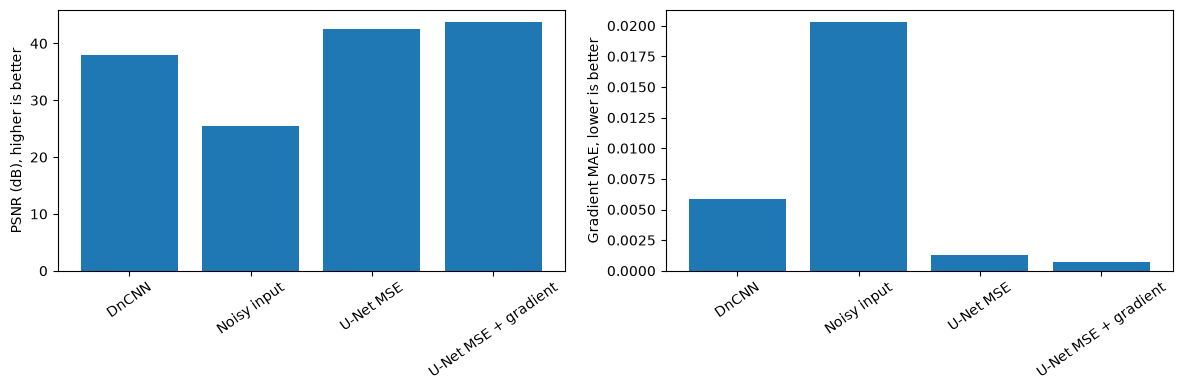

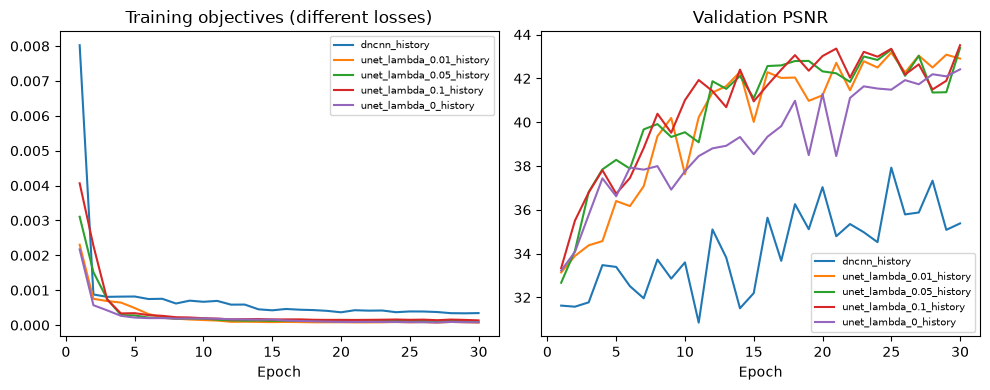

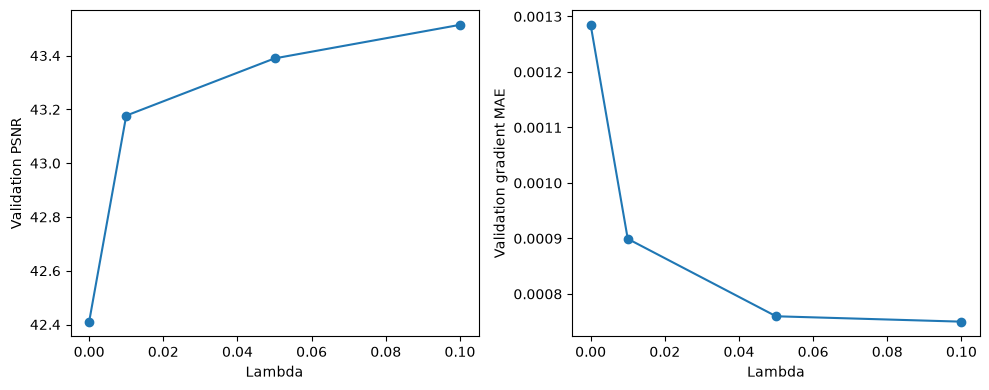

In [14]:
psnr_wide = per_group.pivot(index='group_id', columns='method', values='psnr')
grad_wide = per_group.pivot(index='group_id', columns='method', values='gradient_mae')
paired = pd.DataFrame({
    'edge_minus_mse_psnr': psnr_wide['U-Net MSE + gradient']-psnr_wide['U-Net MSE'],
    'edge_minus_mse_gradient_mae': grad_wide['U-Net MSE + gradient']-grad_wide['U-Net MSE'],
})
paired.to_csv(OUT / 'paired_unet_comparison.csv')
display(paired.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(['psnr','gradient_mae'], axes):
    means = per_group.groupby('method')[metric].mean()
    ax.bar(means.index, means.values)
    ax.set_ylabel('PSNR (dB), higher is better' if metric=='psnr' else 'Gradient MAE, lower is better')
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(OUT / 'metric_comparison.png', dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for path in sorted(OUT.glob('*_history.csv')):
    history = pd.read_csv(path)
    axes[0].plot(history['epoch'], history['train_loss'], label=path.stem)
    axes[1].plot(history['epoch'], history['psnr'], label=path.stem)
axes[0].set_title('Training objectives (different losses)')
axes[1].set_title('Validation PSNR')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / 'training_curves.png', dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(lambda_table['lambda'], lambda_table['psnr'], 'o-')
axes[1].plot(lambda_table['lambda'], lambda_table['gradient_mae'], 'o-')
axes[0].set_ylabel('Validation PSNR')
axes[1].set_ylabel('Validation gradient MAE')
for ax in axes:
    ax.set_xlabel('Lambda')
fig.tight_layout()
fig.savefig(OUT / 'lambda_tradeoff.png', dpi=200)
plt.show()


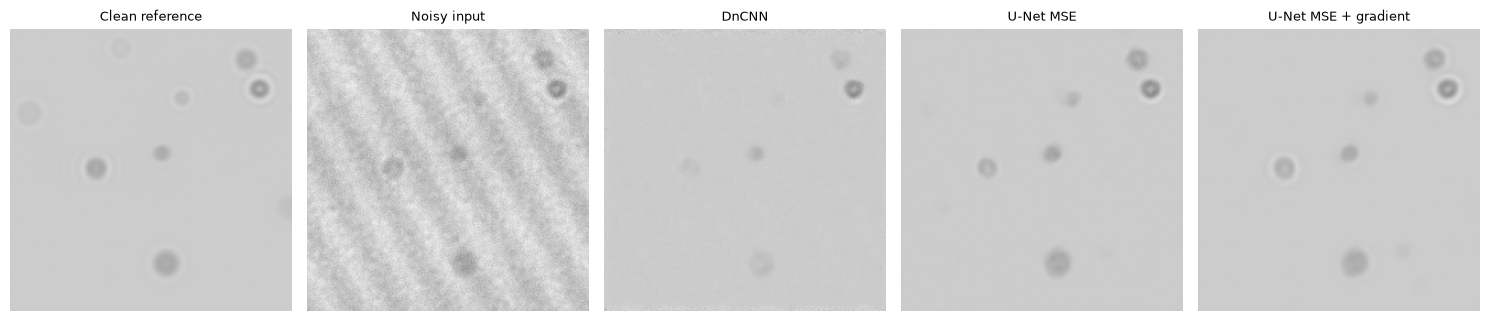

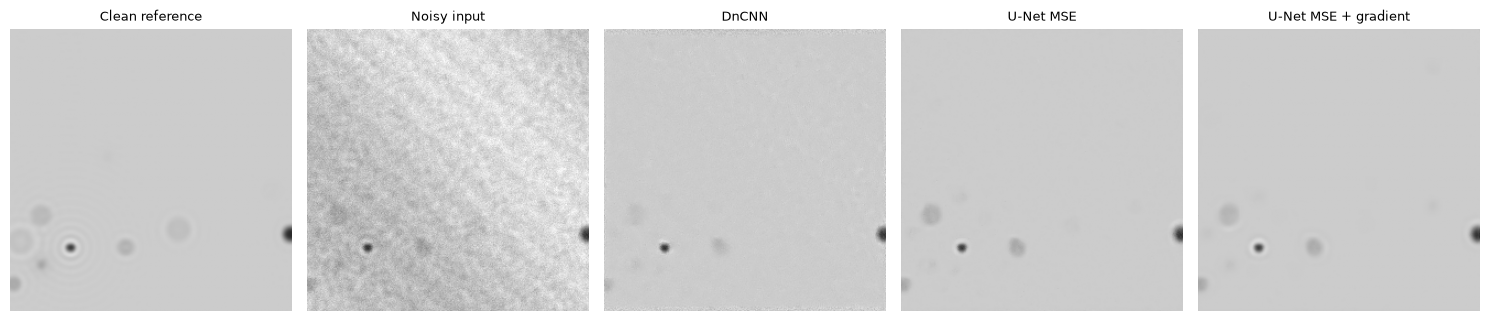

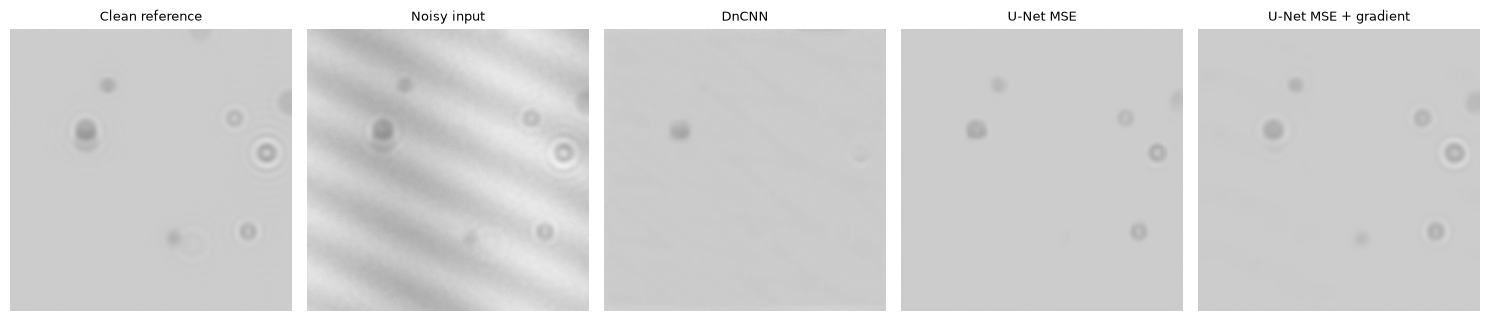

Saved results to: C:\Users\15174\PyCharmMiscProject\results_npy\full_seed_42


In [15]:
method_order = ['Noisy input','DnCNN','U-Net MSE','U-Net MSE + gradient']
for index in comparison_indices:
    _, reference = read_pair(index)
    images = {'Clean reference': reference}
    records_for_image = results[results['index']==index].set_index('method')
    for method in method_order:
        images[method] = np.load(records_for_image.loc[method,'prediction_path'])
    view_list = [('full', None)]
    if index in ROI_BY_INDEX:
        view_list.append(('roi', ROI_BY_INDEX[index]))
    for view_name, rectangle in view_list:
        fig, axes = plt.subplots(1, len(images), figsize=(3*len(images), 3.5), squeeze=False)
        for ax, (name, image) in zip(axes[0], images.items()):
            display_image = crop_roi(image, rectangle) if rectangle is not None else image
            # Identical display limits; display saturation does NOT change saved data.
            ax.imshow(display_image, cmap='gray', vmin=0, vmax=1)
            ax.set_title(name, fontsize=9)
            ax.axis('off')
        fig.tight_layout()
        fig.savefig(OUT / f'comparison_{index:05d}_{view_name}.png', dpi=200, bbox_inches='tight')
        plt.show()
print('Saved results to:', OUT)
